# 2. Solving ordinary differential equations: Accuracy of the Euler and Runge-Kutta methods

**Pin number**: 239

### Solution of ODE by means of Euler and Runge-Kutta methods

We start by assigning values to parameters $PIN$, $a$, $b$, $N$, $h$ and $C$ as well as defining functions $f(x,y)=-Cy-Cx^3-3x^2$ and $y(x)=10\exp(-Cx)-x^3$.

In [141]:
# Define here variables PIN, a, b, N, h, C and assign appropriate values to them

PIN =  239
a = 0.0
b = 5.0
N = 8
h = (b-a)/N
C = 1.5-PIN/750.0
%whos


Variable            Type             Data/Info
----------------------------------------------
C                   float            1.1813333333333333
C_2                 float            120.33333333333333
Euler               function         <function Euler at 0x11114a7a0>
Euler2              function         <function Euler2 at 0x111259300>
Euler2_N            list             n=21
Euler_N             list             n=8
N                   int              8
NamespaceMagics     MetaHasTraits    <class 'IPython.core.magi<...>mespace.NamespaceMagics'>
PIN                 int              239
RK                  function         <function RK at 0x11114b100>
RK_N                list             n=8
a                   float            0.0
b                   float            5.0
coef_Euler          ndarray          2: 2 elems, type `float64`, 16 bytes
coef_RK             ndarray          2: 2 elems, type `float64`, 16 bytes
col_names           list             n=6
collections         m

In [142]:
# Define here the function f(x,y)=-Cy-Cx^3-3x^2 as well as the exact solution y(x)=10*exp(-Cx)-x^3

import numpy as np

def f(x,y):
    f = -C*y - C*x**3 - 3*x**2
    return f

# Provide here the definition of the exact solution y(x)

def y(x):
    y = 10*np.exp(-C*x) - x**3
    return y

**Question 1**. Calculate numerical approximations $y_1,..., y_N$ by means of the Euler and Runge-Kutta methods and compare them to the values of the exact solution $y(x_1),..., y(x_N)$. For this question we use $N=8$ and $h=0.625$.

In [143]:
# Construct here the following lists for the case h=0.625 (corresponding to N=8): 
# - x_values, 
# - y_values
# - y_euler_values
# - y_RK_values

x_values = [a]
y_values = [y(a)]
y_euler_values = [y(a)]
y_RK_values = [y(a)]
h = 0.625

# Calculate the components of these lists for i=1,...,N

for i in range(8):
    x = x_values[-1]

    # Eulers Method
    y_euler = y_euler_values[-1]
    y_euler += h * f(x, y_euler)
    y_euler_values.append(y_euler)

    # Runge-Kutta Method
    y_RK = y_RK_values[-1]
    k1 = f(x, y_RK)
    k2 = f(x + h/2, y_RK + (h*k1)/2)
    k3 = f(x + h/2, y_RK + (h*k2)/2)
    k4 = f(x + h, y_RK + h*k3)
    y_RK += (1/6) * h * (k1 + 2*k2 + 2*k3 + k4)
    y_RK_values.append(y_RK)

    x += h
    x_values.append(x)

    y_values.append(y(x))
    

# Create a table with five columns: i, x_i, y(x_i), y_i Euler, y_i RK

from tabulate import tabulate
tab=[]
for i in range(0,7):
    tab+=[[i,x_values[i],y_values[i],y_euler_values[i],y_RK_values[i]]]

col_names = ["i","x_i","y(x_i)","y_i euler", "y_i RK"] 
print(tabulate(tab, headers=col_names))


  i    x_i      y(x_i)    y_i euler      y_i RK
---  -----  ----------  -----------  ----------
  0  0       10           10          10
  1  0.625    4.53496      2.61667     4.54741
  2  1.25     0.330852    -0.227985    0.334654
  3  1.875   -5.50026     -4.4314     -5.51081
  4  2.5    -15.1033     -12.6183    -15.1288
  5  3.125  -30.2683     -26.557     -30.308
  6  3.75   -52.6152     -47.7918    -52.6684


**Question 2**. Create a figure showing the exact solution $y(x)$ and numerical approximations $y_1,..., y_N$ for the Euler and Runge-Kutta method. Include appropriate axis labels, plot title and legend.

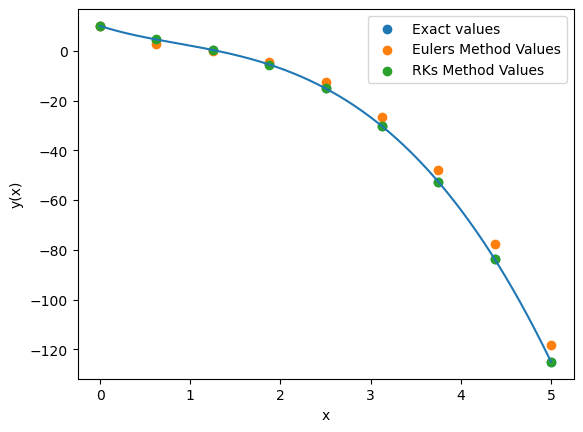

In [144]:
# Plot here the exact values y(x_i) as well as the numerically calculated values y_i for the Euler and Runge-Kutta method
import matplotlib.pyplot as plt

x_values_lin = np.linspace(a, b, 500)
y_values_lin = y(x_values_lin)
plt.plot(x_values_lin, y_values_lin)
plt.xlabel('x')
plt.ylabel('y(x)')
plt.scatter(x_values, y_values,label='Exact values')
plt.scatter(x_values, y_euler_values,label='Eulers Method Values')
plt.scatter(x_values, y_RK_values,label='RKs Method Values')
plt.legend()

### Magnitude of the error at 𝑥=0.5 for values of ℎ corresponding to $N=8,16,...,1024$

We first change the range of $x$ values by evaluating the following cell:

In [145]:
a=0.0
b=0.5

**Question 3**. Write the functions Euler(N) and RK(N) that return the values of $y_N$ for different values of $N$.

In [146]:
# Define here the functions Euler(N) and RK(N) that return the numerical approximation y_N for varying parameters N

def Euler(N):
    h = (b-a)/N
    x = a
    y_euler = y(a)
    for i in range(N):
        y_euler += h * f(x, y_euler)
        x += h
    return y_euler

def RK(N):
    h = (b-a)/N
    x = a
    y_RK = y(a)
    for i in range(N):
        k1 = f(x, y_RK)
        k2 = f(x + h/2, y_RK + (h*k1)/2)
        k3 = f(x + h/2, y_RK + (h*k2)/2)
        k4 = f(x + h, y_RK + h*k3)
        y_RK += (1/6) * h * (k1 + 2*k2 + 2*k3 + k4)
        x += h
    return y_RK


**Question 4**. Calculate the absolute values of the error $|y_N-y(x_N)|$ for $N=8,16,...,1024$ at $x_N=b=0.5$ for both Euler and
Runge-Kutta methods. Also calculate the natural logarithm of the absolute error, i.e., $\ln|y_N-y(x_N)|$. Tabulate your results in a table with six columns: $N$, $y(b)$, $y_N$ Euler, $|y_N-y(x_N)|$ Euler, $y_N$ Runge-Kutta, $|y_N-y(x_N)|$ Runge-Kutta.

In [147]:
# Calculate here the absolute values of the error |y_N-y(x_N)| and their natural logarithm for Euler and Runge-Kutta methods.
# Tabulate your results in six columns: "N","y(b)","y_N Euler","error Euler","y_N RK","error RK"

data_N = [8, 16, 32, 64, 128, 256, 512, 1024]

ln_data_N = np.log(data_N)

Euler_N = [Euler(i) for i in data_N]
error_Euler_N = [abs(i - y(b)) for i in Euler_N]
ln_error_Euler_N = [np.log(i) for i in error_Euler_N]

RK_N = [RK(i) for i in data_N]
error_RK_N = [abs(i - y(b)) for i in RK_N]
ln_error_RK_N = [np.log(i) for i in error_RK_N]

tab=[]
for i in range(8):
    tab+=[[data_N[i],y(b),Euler_N[i],error_Euler_N[i],RK_N[i],error_RK_N[i]]]

col_names = ["N","y(b)","y_N Euler","error Euler","y_N RK","error RK"] 
print(tabulate(tab, headers=col_names))

   N     y(b)    y_N Euler    error Euler    y_N RK     error RK
----  -------  -----------  -------------  --------  -----------
   8  5.41458      5.3082     0.106382      5.41458  5.3205e-07
  16  5.41458      5.36267    0.0519048     5.41458  3.15882e-08
  32  5.41458      5.38894    0.0256427     5.41458  1.92384e-09
  64  5.41458      5.40183    0.0127453     5.41458  1.18693e-10
 128  5.41458      5.40822    0.00635383    5.41458  7.36744e-12
 256  5.41458      5.41141    0.00317223    5.41458  4.56524e-13
 512  5.41458      5.41299    0.00158495    5.41458  2.22045e-14
1024  5.41458      5.41379    0.000792181   5.41458  8.88178e-16


**Question 5**. Determine linear fits of $\ln|y_N-y(x_N)|$ against $\ln(N)$ for $N=8,16,...,1024$ for both Euler and
Runge-Kutta methods. 

In [148]:
# Use this cell to determine a linear fit of ln(|y_N-y(x_N)|) against ln(N) for the Euler and Runge-Kutta method

coef_Euler = np.polyfit(ln_data_N, ln_error_Euler_N, 1)
fit_Euler = np.poly1d(coef_Euler)
print('The fit function for the Euler method is:', coef_Euler[0],'*x +',coef_Euler[1])


coef_RK = np.polyfit(ln_data_N, ln_error_RK_N, 1)
fit_RK = np.poly1d(coef_RK)
print('The fit function for the RK method is:', coef_RK[0],'*x +',coef_RK[1])



The fit function for the Euler method is: -1.0083393577499504 *x + -0.16010726649452753
The fit function for the RK method is: -4.124284838351722 *x + -5.766384272363421


**Question 6**. Create a figure showing $\ln|y_N-y(x_N)|$ against $\ln(N)$ for $N=8,16,...,1024$ for both Euler and
Runge-Kutta methods as well as the linear fits to the data.

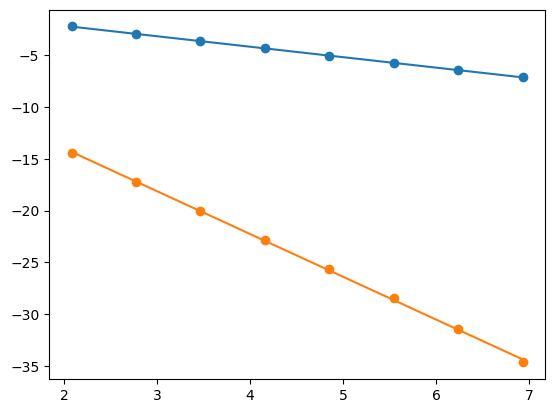

In [149]:
# Create here a figure showing ln(|y_N-y(x_N)|) against ln(N) for the Euler and Runge-Kutta method

plt.scatter(ln_data_N, ln_error_Euler_N)
plt.plot(ln_data_N,fit_Euler(ln_data_N),label=f'Eulers Method: {coef_Euler[0]:.2f}x+{coef_Euler[1]:.2f}')

plt.scatter(ln_data_N, ln_error_RK_N)
plt.plot(ln_data_N,fit_RK(ln_data_N),label=f'RK Method: {coef_RK[0]:.2f}x+{coef_RK[1]:.2f}')



Brief comments on the slopes of linear fits:

### Stability of the Euler method

In order to investigate the stability of the Euler method for different values of $N$, we first need to assign new values to variables $a$, $b$ and $C_2$ as well as define new functions $f_2(x,y)=-C_2y$ and $y_2(x)=\exp(-C_2x)$.

In [150]:
# Assign here new values to variables a, b, and C_2
a = 0
b = 0.5
C_2 = 200 - (239/3)


In [151]:
# Use this cell to define the function f2(x,y)=-C_2y and the exact solution y2(x)=exp(-C_2x)

def f2(x, y):
    value = -C_2 * y
    return value

def y2(x):
    value = np.exp(-C_2 * x)
    return value

**Question 7**.  Define a new function Euler2(N) that returns the approximate value $y_N$ calculated by means of the Euler method at $x=b=0.5$ for varying $N$. Consider the range $20\leq N \leq 40$ and calculate the absolute value of errors $|y_N - y_2(b)|$ for these values of $N$.

In [152]:
# Use this cell to define the function Euler2(N) and to calculate the absolute errors |y_N-y2(b)| for N=20,21,...40
def Euler2(N):
    h = (b-a)/N
    x = a
    y_euler = y(a)
    for i in range(N):
        y_euler += h * f2(x, y_euler)
        x += h
    return y_euler    

data_N = np.arange(20, 41)

Euler2_N = [Euler2(i) for i in data_N]
error_Euler2_N = [abs(i - y2(b)) for i in Euler2_N]
ln_error_Euler2_N = [np.log(i) for i in error_Euler2_N]


**Question 8**. Create a figure showing a scatter plot of the absolute values of errors $|y_N - y_2(b)|$ for $20\leq N \leq 40$. Label the axes of your figure appropriately and provide a suitable plot title.

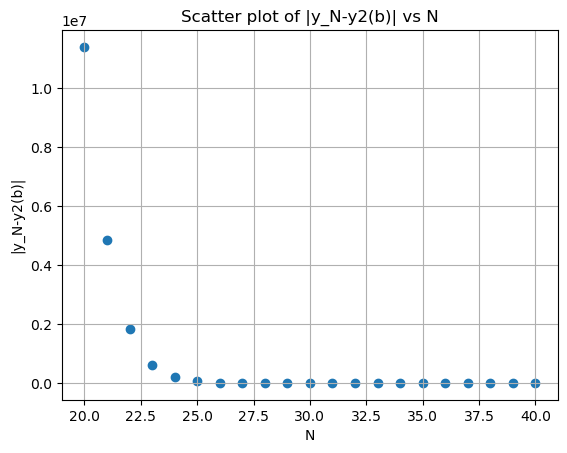

In [153]:
# Use this cell to create a scatter plot of |y_N-y2(b)| against N.

plt.scatter(data_N,error_Euler2_N)
plt.xlabel("N")
plt.ylabel("|y_N-y2(b)|")
plt.title("Scatter plot of |y_N-y2(b)| vs N")
plt.grid()

It can be seen from the graph that the onset of stability occurs approximately for the following value of $N$: 26

This value of $N$ can be expected because we know that for it to become stable |1 − hC2 | ≤ 1 and since h = (b-a)/N we get to the condition of (b-a)C2/2 ≤ N, and for our initial conditions of b = 0.5 and a = 0, C2/4 ≤ N therefore 30.08 ≤  N. However we only got 25, this is because instability is happens slowly and may take a few more steps before blowing up.